In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import *


INFO       Cache size for target 'cython': 2403 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [ ]:
start_scope()

SEED = 2
seed(SEED)
rng = np.random.default_rng(SEED)

# Simulation
DT = 0.02*ms        You would fight me to say you want to fight me. South of nowhere you like I want to fight you why you want to fight me why you fight me to fight musique, since I batrick, on the count je suis prêts. I'm sure I don't set
REC_DT = 0.20*ms
SIM_TIME = 4*second
DBS_ONSET = 1*second
defaultclock.dt = DT

# Populations
NE = 400
NI = 100

# HH membrane
CM = 200*pF
G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

# Synapses
E_AMPA = 0*mV
E_GABA = -80*mV

# Fixed fast AMPA / GABA_A kinetics.
# Tune conductances / drive for beta, not these time constants.
TAU_AMPA_RISE  = 0.5*ms
TAU_AMPA_DECAY = 2.0*ms
TAU_GABA_RISE  = 0.5*ms
TAU_GABA_DECAY = 8.0*ms

def jump_scale(tau_rise, tau_decay):
    # For dx/dt=-x/tau_decay and dg/dt=(x-g)/tau_rise,
    # return the input jump scale that makes peak(g) ~= W.
    tr = float(tau_rise/ms)
    td = float(tau_decay/ms)
    t_peak = tr*td/(td-tr) * np.log(td/tr)
    peak = td/(td-tr) * (
        np.exp(-t_peak/td) - np.exp(-t_peak/tr)
    )
    return 1.0/peak

AMPA_JUMP_SCALE = jump_scale(TAU_AMPA_RISE, TAU_AMPA_DECAY)
GABA_JUMP_SCALE = jump_scale(TAU_GABA_RISE, TAU_GABA_DECAY)

W_EE = 0.8*nS
W_EI = 1.5*nS
W_IE = 5.0*nS
W_II = 3.0*nS

P_EE = 0.08
P_EI = 0.10
P_IE = 0.10
P_II = 0.10

# Background
I_TONIC_E = 0.35*nA
I_TONIC_I = 0.30*nA

N_EXT_E = 300
N_EXT_I = 250
RATE_EXT_E = 8*Hz
RATE_EXT_I = 8*Hz
W_EXT_E = 1.3*nS
W_EXT_I = 1.1*nS

# ------------------------------------------------------------
# DBS
# ------------------------------------------------------------
DBS_FREQ = 55*Hz
DBS_PULSE_WIDTH = 60*us

# Easy parameter to change:
DBS_AMP_MA = 5.0

# Free model transfer coefficient.
# This is NOT a physical conversion from electrode mA to soma nA.
DBS_GAIN_NA_PER_MA = 1.0*nA


DBS_TARGET_E = 1.0
DBS_TARGET_I = 1.0

# Build pulse train
dt_s = float(DT/second)
T_s = float(SIM_TIME/second)
onset_s = float(DBS_ONSET/second)
freq_hz = float(DBS_FREQ/Hz)
pw_s = float(DBS_PULSE_WIDTH/second)

n_steps = int(np.ceil(T_s/dt_s))
dbs_t = np.arange(n_steps)*dt_s
dbs_waveform_nA = np.zeros(n_steps)

after_onset = dbs_t >= onset_s
phase = np.mod(dbs_t[after_onset] - onset_s, 1.0/freq_hz)
pulse_mask = phase < pw_s

dbs_waveform_nA[after_onset] = (
    DBS_AMP_MA
    * float(DBS_GAIN_NA_PER_MA/nA)
    * pulse_mask.astype(float)
)

dbs_ta = TimedArray(dbs_waveform_nA*nA, dt=DT)

# ------------------------------------------------------------
# HH equations
# ------------------------------------------------------------
eqs = r'''
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + gA*(E_AMPA-v)
    + gG*(E_GABA-v)
    + I_tonic
    + I_dbs
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dxA/dt = -xA/TAU_AMPA_DECAY : siemens
dgA/dt = (xA-gA)/TAU_AMPA_RISE : siemens

dxG/dt = -xG/TAU_GABA_DECAY : siemens
dgG/dt = (xG-gG)/TAU_GABA_RISE : siemens

I_tonic : amp
dbs_target : 1
I_dbs = dbs_target * dbs_ta(t) : amp
'''

namespace = {
    'CM': CM, 'G_NA': G_NA, 'G_K': G_K, 'G_L': G_L,
    'E_NA': E_NA, 'E_K': E_K, 'E_L': E_L,
    'E_AMPA': E_AMPA, 'E_GABA': E_GABA,
    'TAU_AMPA_RISE': TAU_AMPA_RISE,
    'TAU_AMPA_DECAY': TAU_AMPA_DECAY,
    'TAU_GABA_RISE': TAU_GABA_RISE,
    'TAU_GABA_DECAY': TAU_GABA_DECAY,
    'dbs_ta': dbs_ta
}

# Neurons
E = NeuronGroup(
    NE, eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='E'
)

I = NeuronGroup(
    NI, eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='I'
)

for G in (E, I):
    G.v = -65*mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318
    G.xA = 0*nS
    G.gA = 0*nS
    G.xG = 0*nS
    G.gG = 0*nS

E.I_tonic = np.clip(
    rng.normal(float(I_TONIC_E/nA), 0.05, NE), 0.05, None
)*nA

I.I_tonic = np.clip(
    rng.normal(float(I_TONIC_I/nA), 0.04, NI), 0.05, None
)*nA

E.dbs_target = DBS_TARGET_E
I.dbs_target = DBS_TARGET_I

# Sparse random recurrent connectivity
S_EE = Synapses(
    E, E,
    on_pre='xA_post += AMPA_JUMP_SCALE*W_EE',
    namespace={
        'W_EE': W_EE,
        'AMPA_JUMP_SCALE': AMPA_JUMP_SCALE
    },
    name='S_EE'
)
S_EE.connect(condition='i != j', p=P_EE)
S_EE.delay = '1*ms + rand()*2*ms'

S_EI = Synapses(
    E, I,
    on_pre='xA_post += AMPA_JUMP_SCALE*W_EI',
    namespace={
        'W_EI': W_EI,
        'AMPA_JUMP_SCALE': AMPA_JUMP_SCALE
    },
    name='S_EI'
)
S_EI.connect(p=P_EI)
S_EI.delay = '1*ms + rand()*2*ms'

S_IE = Synapses(
    I, E,
    on_pre='xG_post += GABA_JUMP_SCALE*W_IE',
    namespace={
        'W_IE': W_IE,
        'GABA_JUMP_SCALE': GABA_JUMP_SCALE
    },
    name='S_IE'
)
S_IE.connect(p=P_IE)
S_IE.delay = '2*ms + rand()*3*ms'

S_II = Synapses(
    I, I,
    on_pre='xG_post += GABA_JUMP_SCALE*W_II',
    namespace={
        'W_II': W_II,
        'GABA_JUMP_SCALE': GABA_JUMP_SCALE
    },
    name='S_II'
)
S_II.connect(condition='i != j', p=P_II)
S_II.delay = '2*ms + rand()*3*ms'

# Poisson background
P_EXT_E = PoissonInput(
    E, 'xA',
    N=N_EXT_E,
    rate=RATE_EXT_E,
    weight=AMPA_JUMP_SCALE*W_EXT_E
)

P_EXT_I = PoissonInput(
    I, 'xA',
    N=N_EXT_I,
    rate=RATE_EXT_I,
    weight=AMPA_JUMP_SCALE*W_EXT_I
)

# Monitors
M_E = StateMonitor(E, ['v', 'gA', 'gG'],
                   record=True, dt=REC_DT, name='M_E')
M_I = StateMonitor(I, ['v'],
                   record=True, dt=REC_DT, name='M_I')

SP_E = SpikeMonitor(E, name='SP_E')
SP_I = SpikeMonitor(I, name='SP_I')

RATE_E = PopulationRateMonitor(E, name='RATE_E')
RATE_I = PopulationRateMonitor(I, name='RATE_I')

net = Network(
    E, I,
    S_EE, S_EI, S_IE, S_II,
    P_EXT_E, P_EXT_I,
    M_E, M_I, SP_E, SP_I, RATE_E, RATE_I
)

# ------------------------------------------------------------
# Analysis helpers
# ------------------------------------------------------------
def population_lfp_proxy():
    I_AMPA = np.asarray((M_E.gA * (E_AMPA - M_E.v))/nA)
    I_GABA = np.asarray((M_E.gG * (E_GABA - M_E.v))/nA)

    # Signed population synaptic-current proxy.
    # Avoid abs() because rectification can create a spurious 2*f component.
    lfp_AMPA = -np.mean(I_AMPA, axis=0)
    lfp_GABA = -np.mean(I_GABA, axis=0)
    lfp = lfp_AMPA + lfp_GABA

    return np.asarray(M_E.t/second), lfp


def single_neuron_input_proxy(chosen_idx):
    I_AMPA = np.asarray(
        (M_E.gA[chosen_idx]*(E_AMPA - M_E.v[chosen_idx]))/nA
    )
    I_GABA = np.asarray(
        (M_E.gG[chosen_idx]*(E_GABA - M_E.v[chosen_idx]))/nA
    )
    return -(I_AMPA + I_GABA)


def print_basic_rates():
    sim_s = float(SIM_TIME/second)
    onset_s = float(DBS_ONSET/second)

    tE = np.asarray(SP_E.t/second)
    tI = np.asarray(SP_I.t/second)

    off_E = np.sum(tE < onset_s)/(NE*onset_s)
    off_I = np.sum(tI < onset_s)/(NI*onset_s)

    on_duration = sim_s-onset_s
    on_E = np.sum(tE >= onset_s)/(NE*on_duration)
    on_I = np.sum(tI >= onset_s)/(NI*on_duration)

    print(f'DBS OFF E rate: {off_E:.2f} Hz/neuron')
    print(f'DBS OFF I rate: {off_I:.2f} Hz/neuron')
    print(f'DBS ON  E rate: {on_E:.2f} Hz/neuron')
    print(f'DBS ON  I rate: {on_I:.2f} Hz/neuron')


def plot_dbs_summary(chosen_idx=200, fmax=140):
    t = np.asarray(M_E.t/second)
    lfp_t, lfp = population_lfp_proxy()
    single_input = single_neuron_input_proxy(chosen_idx)
    onset_s = float(DBS_ONSET/second)

    # Selected neuron, single-cell input, population LFP
    fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

    ax[0].plot(t, np.asarray(M_E.v[chosen_idx]/mV), lw=0.55)
    ax[0].axvline(onset_s, ls='--')
    ax[0].set_ylabel('E V (mV)')
    ax[0].set_title(f'Chosen E neuron {chosen_idx}')

    ax[1].plot(t, single_input, lw=0.6)
    ax[1].axvline(onset_s, ls='--')
    ax[1].set_ylabel('Single-cell input')

    ax[2].plot(lfp_t, lfp, lw=0.65)
    ax[2].axvline(onset_s, ls='--', label='DBS ON')
    ax[2].set_ylabel('Population LFP proxy')
    ax[2].set_xlabel('Time (s)')
    ax[2].legend()

    plt.tight_layout()
    plt.show()

    # Raster
    plt.figure(figsize=(13, 4))
    plt.plot(np.asarray(SP_E.t/second),
             np.asarray(SP_E.i),
             '.', markersize=1.5)
    plt.axvline(onset_s, ls='--', label='DBS ON')
    plt.xlabel('Time (s)')
    plt.ylabel('E neuron index')
    plt.title('Excitatory spike raster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Population rates
    plt.figure(figsize=(13, 4))
    plt.plot(
        RATE_E.t/second,
        RATE_E.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='E population rate'
    )
    plt.plot(
        RATE_I.t/second,
        RATE_I.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='I population rate'
    )
    plt.axvline(onset_s, ls='--', label='DBS ON')
    plt.xlabel('Time (s)')
    plt.ylabel('Population rate (Hz)')
    plt.title('Smoothed population firing rates')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # PSD: OFF vs ON
    fs = 1.0/float(REC_DT/second)
    off = (lfp_t >= 0.2) & (lfp_t < onset_s)
    on = lfp_t >= onset_s + 0.3

    plt.figure(figsize=(10, 5))

    for mask, label in [(off, 'DBS OFF'), (on, 'DBS ON')]:
        x = signal.detrend(lfp[mask])
        f, pxx = signal.welch(
            x,
            fs=fs,
            nperseg=min(len(x), int(0.75*fs))
        )
        keep = (f >= 5) & (f <= fmax)
        plt.semilogy(f[keep], pxx[keep], label=label)

    plt.axvspan(13, 30, alpha=0.10, label='beta')
    plt.axvline(27.5, ls='--', lw=1, label='55/2')
    plt.axvline(55.0, ls='--', lw=1, label='55 Hz')
    plt.axvline(82.5, ls='--', lw=1, label='3x55/2')
    plt.axvline(110.0, ls='--', lw=1, label='2x55')

    plt.xlabel('Frequency (Hz)')
    plt.ylabel('PSD')
    plt.title(f'DBS OFF vs ON ({DBS_AMP_MA:g} mA label)')
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

    # Spectrogram
    nper = int(0.60*fs)
    nover = int(0.52*fs)

    f_s, tt, Sxx = signal.spectrogram(
        signal.detrend(lfp),
        fs=fs,
        nperseg=nper,
        noverlap=nover,
        scaling='density',
        mode='psd'
    )

    keep = (f_s >= 5) & (f_s <= fmax)

    plt.figure(figsize=(13, 5))
    plt.pcolormesh(
        tt,
        f_s[keep],
        10*np.log10(Sxx[keep] + 1e-18),
        shading='auto'
    )
    plt.axvline(onset_s, ls='--', label='DBS ON')
    plt.axhline(27.5, ls='--', lw=1)
    plt.axhline(55.0, ls='--', lw=1)
    plt.axhline(82.5, ls='--', lw=1)
    plt.axhline(110.0, ls='--', lw=1)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Population LFP proxy — 55 Hz DBS')
    plt.colorbar(label='Power (dB, arbitrary)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Actual pulse shape
    zoom = (dbs_t >= onset_s) & (dbs_t <= onset_s + 0.040)

    plt.figure(figsize=(10, 3))
    plt.step(
        1000*(dbs_t[zoom]-onset_s),
        dbs_waveform_nA[zoom],
        where='post'
    )
    plt.xlabel('Time after DBS onset (ms)')
    plt.ylabel('Effective model current (nA)')
    plt.title('55 Hz DBS, 60 us pulses')
    plt.tight_layout()
    plt.show()

    return lfp


In [6]:
net.run(SIM_TIME, report='text')

print_basic_rates()


Starting simulation at t=0. s for a duration of 4. s
1.54932 s (38%) simulated in 10s, estimated 16s remaining.
3.1415 s (78%) simulated in 20s, estimated 5s remaining.
4. s (100%) simulated in 27s
DBS OFF E rate: 14.36 Hz/neuron
DBS OFF I rate: 10.48 Hz/neuron
DBS ON  E rate: 14.79 Hz/neuron
DBS ON  I rate: 13.14 Hz/neuron


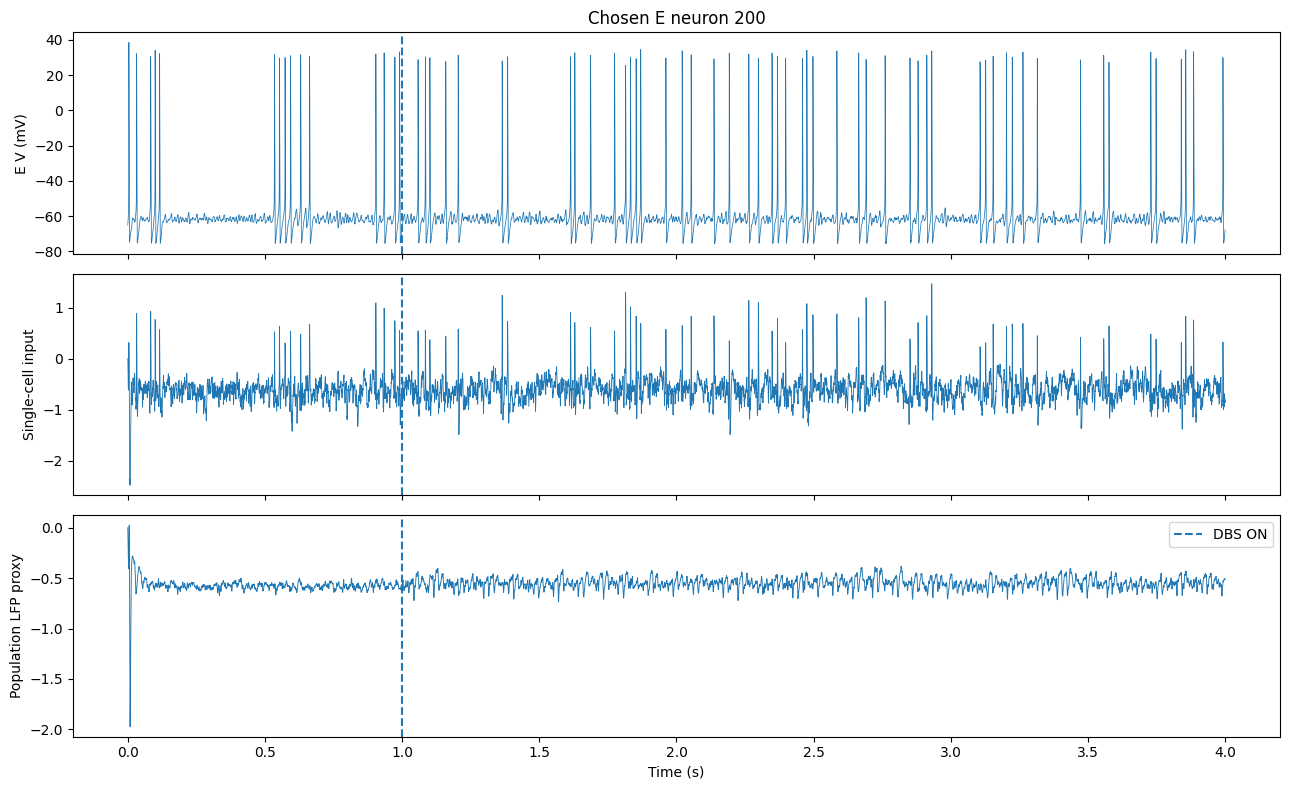

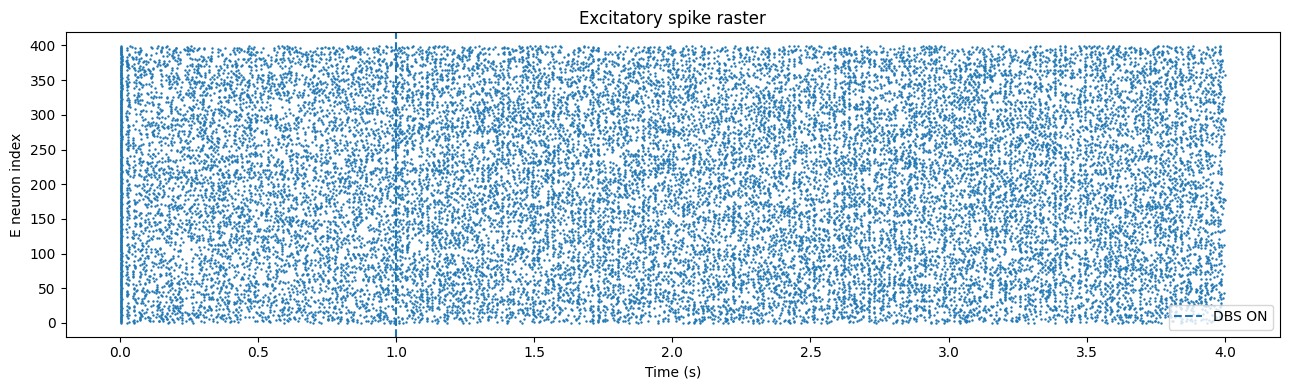

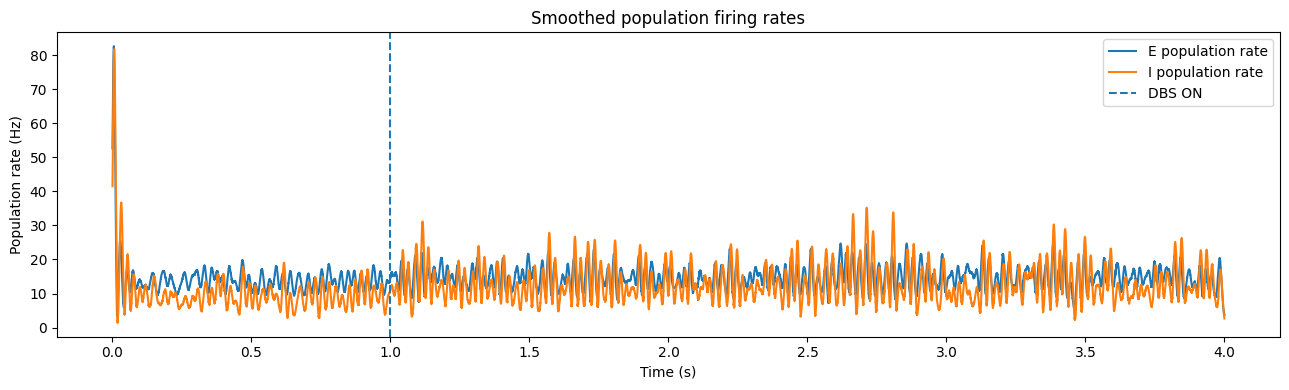

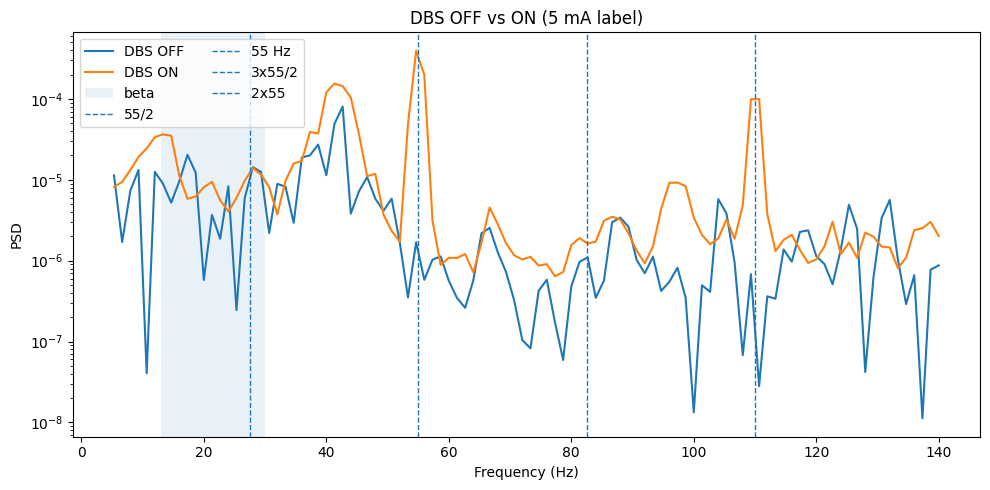

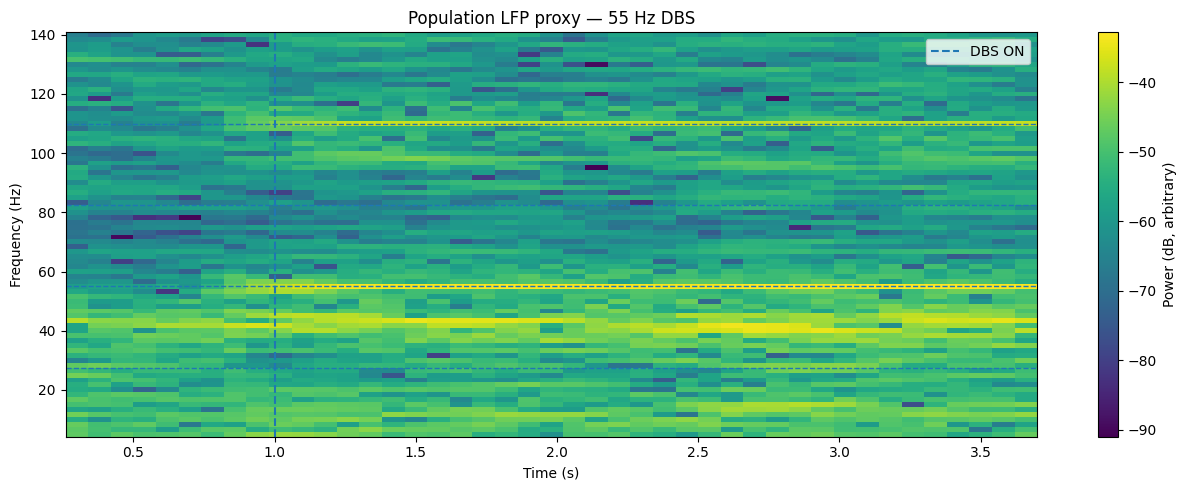

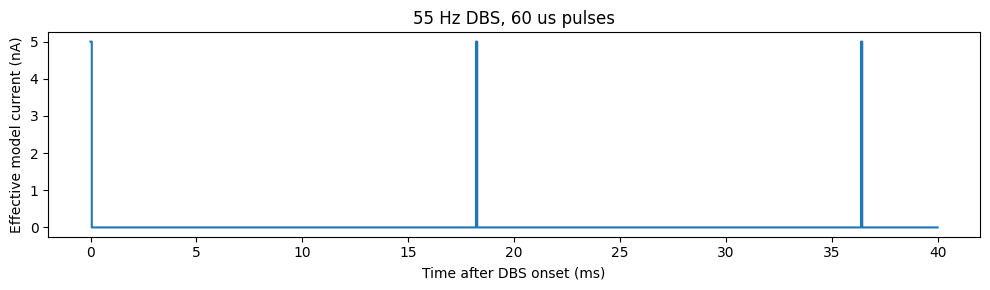

In [7]:
chosen_idx = 200

lfp = plot_dbs_summary(
    chosen_idx=chosen_idx,
    fmax=140
)
